# ESCAPE solver-mode comparison (DIII-D, Dunsmore database)

The 8 runs submitted by `submit_scan.sh`: SC model (1D, 3D) x implementation (firedrake, scipy) x location of the $n_e$ gradient BC (inner, outer), read from `outputs/DIIIDDunsmore_ESCAPE_{model}{implementation}{bc}{RUN_SUFFIX}/{EQUIL}/neouter0_fp0/`.

A run counts as **converged** when `scan_SCfp_ESCAPE.py` wrote `out_dict.npy` (ESCAPE_solve returned); a `failed.npy` means it raised.

In [1]:
# --- Load every run of the 8 solver-mode cases ---
# deserialized outside the solver process, so it is replaced by None on load. Unpickling
# the state also needs the ESCAPE repo root on sys.path (it references src.* classes).
#   experimental n_e  out_dict['profiles']  'n_e' on 'psin_ne'        [m^-3]
#   simulated n_e     out_dict['state']     'n_e' on 'psi_ne_eval'     [m^-3]
#                     (core raised to the solved pedestal, after the last ESCAPE iteration)
#   experimental p    n_e * T_e * (1 + T_rat) from out_dict['profiles'] (the database has no main-ion
#                     channels; same n_i = n_e, T_i = T_rat * T_e closure the run was fed)
#   simulated p       n_e * T_e + n_i * T_i from out_dict['state']      [Pa]
#   first-iteration   ne_and_Te_iter_0.npy  'n_e' on 'psi_ne_eval'    [m^-3]
#   simulated n_e     (Saarelma-Connor solve only, before any EPEDNN feedback; also
#                     present for runs whose later ESCAPE iterations failed)

import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from numpy.lib import format as npy_format

ROOT = Path.cwd().parent.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# ------------------------------------------------------------------ user input
SC_MODELS = ['1D', '3D']                      # figure rows
SC_IMPLEMENTATIONS = ['firedrake', 'scipy']   # figure columns (outer loop)
NE_GRAD_BC_LOCS = ['inner', 'outer']          # figure columns (inner loop)
RUN_SUFFIX = '_10272026_samulidamp_complete'                             # output-directory version ('' for the first scan)
RUN_SUBDIR = 'neouter0_fp0'                   # single free-parameter combination per equilibrium
PSI_NE = 0.85                                 # psi_N at which both densities are read
AXIS_MAX = 12                                 # scatter axis limit in 10^19 m^-3
P_AXIS_MAX = 50                               # pressure scatter axis limit in kPa
BAND_FRAC = 0.30                              # shaded +/- band around the 1:1 line
# -----------------------------------------------------------------------------

CASES = [(m, impl, bc) for m in SC_MODELS
         for impl in SC_IMPLEMENTATIONS for bc in NE_GRAD_BC_LOCS]


def case_dir(model, impl, bc):
    return Path(f'outputs/DIIIDDunsmore_ESCAPE_{model}{impl}{bc}{RUN_SUFFIX}')


def case_label(model, impl, bc):
    return f'{model} {impl} {bc}'


class _JuliaStub:
    """Stand-in for juliacall.AnyValue: deserializes to None."""
    @classmethod
    def _jl_deserialize(cls, *args):
        return None


class _NoJuliaUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module.startswith('juliacall'):
            return _JuliaStub
        return super().find_class(module, name)


def load_out_dict(fp):
    """np.load(fp, allow_pickle=True).item(), with juliacall objects replaced by None."""
    with open(fp, 'rb') as f:
        version = npy_format.read_magic(f)
        npy_format._read_array_header(f, version)
        return _NoJuliaUnpickler(f).load().item()


def ne_at(psi_src, ne_src, psi_N):
    """Electron density [m^-3] at psi_N, or NaN if psi_N is off the grid."""
    psi_src = np.asarray(psi_src, dtype=float)
    ne_src = np.asarray(ne_src, dtype=float)
    if psi_N < psi_src.min() or psi_N > psi_src.max():
        return np.nan
    order = np.argsort(psi_src, kind='stable')
    return float(np.interp(psi_N, psi_src[order], ne_src[order]))


KEV_TO_J = 1.602176634e-16


def p_exp_at(profiles, T_rat, psi_N):
    """Experimental total pressure [Pa] at psi_N: n_e * T_e * (1 + T_rat)."""
    n_e = ne_at(profiles['psin_ne'], profiles['n_e'], psi_N)       # m^-3
    T_e = ne_at(profiles['psin_Te'], profiles['T_e'], psi_N)       # keV
    return n_e * T_e * (1 + T_rat) * KEV_TO_J


def p_sim_at(s, psi_N):
    """Simulated total pressure [Pa] at psi_N: n_e * T_e + n_i * T_i."""
    return (ne_at(s['psi_ne_eval'], s['n_e'], psi_N) * ne_at(s['psi_Te_eval'], s['T_e'], psi_N)
            + ne_at(s['psi_ni_eval'], s['n_i'], psi_N) * ne_at(s['psi_Ti_eval'], s['T_i'], psi_N)
            ) * KEV_TO_J


def load_case(model, impl, bc, psi_ne=PSI_NE):
    """Per-equilibrium results of one case.

    Returns dict with 'runs' (converged: equil, ne_exp, ne_sim [10^19 m^-3],
    p_exp, p_sim [kPa], runtime [s]), 'first' (every run whose first ESCAPE iteration
    finished: equil, ne_sim [10^19 m^-3]), 'failed' and 'pending' (equilibrium tags),
    and 'free_params' of the first run.
    """
    root = case_dir(model, impl, bc)
    runs, first, failed, pending, free_params = [], [], [], [], None
    for equil_dir in sorted(p for p in root.iterdir() if p.is_dir()):
        run_dir = equil_dir / RUN_SUBDIR
        first_fp = run_dir / 'ne_and_Te_iter_0.npy'
        if first_fp.exists():
            f0 = load_out_dict(first_fp)
            first.append({
                'equil':  equil_dir.name,
                'ne_sim': ne_at(f0['psi_ne_eval'], f0['n_e'], psi_ne) / 1e19,
            })
        out_fp = run_dir / 'out_dict.npy'
        if not out_fp.exists():
            (failed if (run_dir / 'failed.npy').exists() else pending).append(equil_dir.name)
            continue
        d = load_out_dict(out_fp)
        s = d['state']
        free_params = free_params or d['free_params']
        runs.append({
            'equil':   equil_dir.name,
            'ne_exp':  ne_at(d['profiles']['psin_ne'], d['profiles']['n_e'], psi_ne) / 1e19,
            'ne_sim':  ne_at(s['psi_ne_eval'], s['n_e'], psi_ne) / 1e19,
            'p_exp':   p_exp_at(d['profiles'], s['T_rat'], psi_ne) / 1e3,
            'p_sim':   p_sim_at(s, psi_ne) / 1e3,
            'runtime': float(d['ESCAPE_runtime']),
        })
    return {'runs': runs, 'first': first, 'failed': failed, 'pending': pending,
            'free_params': free_params}


results = {}
for case in CASES:
    if not case_dir(*case).is_dir():
        print(f'{case_dir(*case)} not found, skipped')
        continue
    results[case] = r = load_case(*case)
    n_tot = len(r['runs']) + len(r['failed']) + len(r['pending'])
    print(f'{case_label(*case):22s} converged {len(r["runs"]):3d}/{n_tot}, '
          f'failed {len(r["failed"]):3d}, pending {len(r["pending"]):3d}')

# Experimental n_e depends only on the equilibrium, so first-iteration points of runs that
# later failed take it from any case in which that equilibrium converged.
ne_exp_by_equil = {x['equil']: x['ne_exp'] for r in results.values() for x in r['runs']}


outputs/DIIIDDunsmore_ESCAPE_1Dfiredrakeinner_10272026_samulidamp_complete not found, skipped
outputs/DIIIDDunsmore_ESCAPE_1Dfiredrakeouter_10272026_samulidamp_complete not found, skipped
outputs/DIIIDDunsmore_ESCAPE_1Dscipyinner_10272026_samulidamp_complete not found, skipped
1D scipy outer         converged  55/55, failed   0, pending   0
outputs/DIIIDDunsmore_ESCAPE_3Dfiredrakeinner_10272026_samulidamp_complete not found, skipped
outputs/DIIIDDunsmore_ESCAPE_3Dfiredrakeouter_10272026_samulidamp_complete not found, skipped
outputs/DIIIDDunsmore_ESCAPE_3Dscipyinner_10272026_samulidamp_complete not found, skipped
outputs/DIIIDDunsmore_ESCAPE_3Dscipyouter_10272026_samulidamp_complete not found, skipped


## Simulated vs experimental $n_{e,ped}$

Same quantity as the single-case figure: $n_e$ at $\psi_N = 0.85$ (the SC solver's inner boundary), one point per converged equilibrium. Rows: SC model; columns: implementation and $n_e$-gradient BC location.

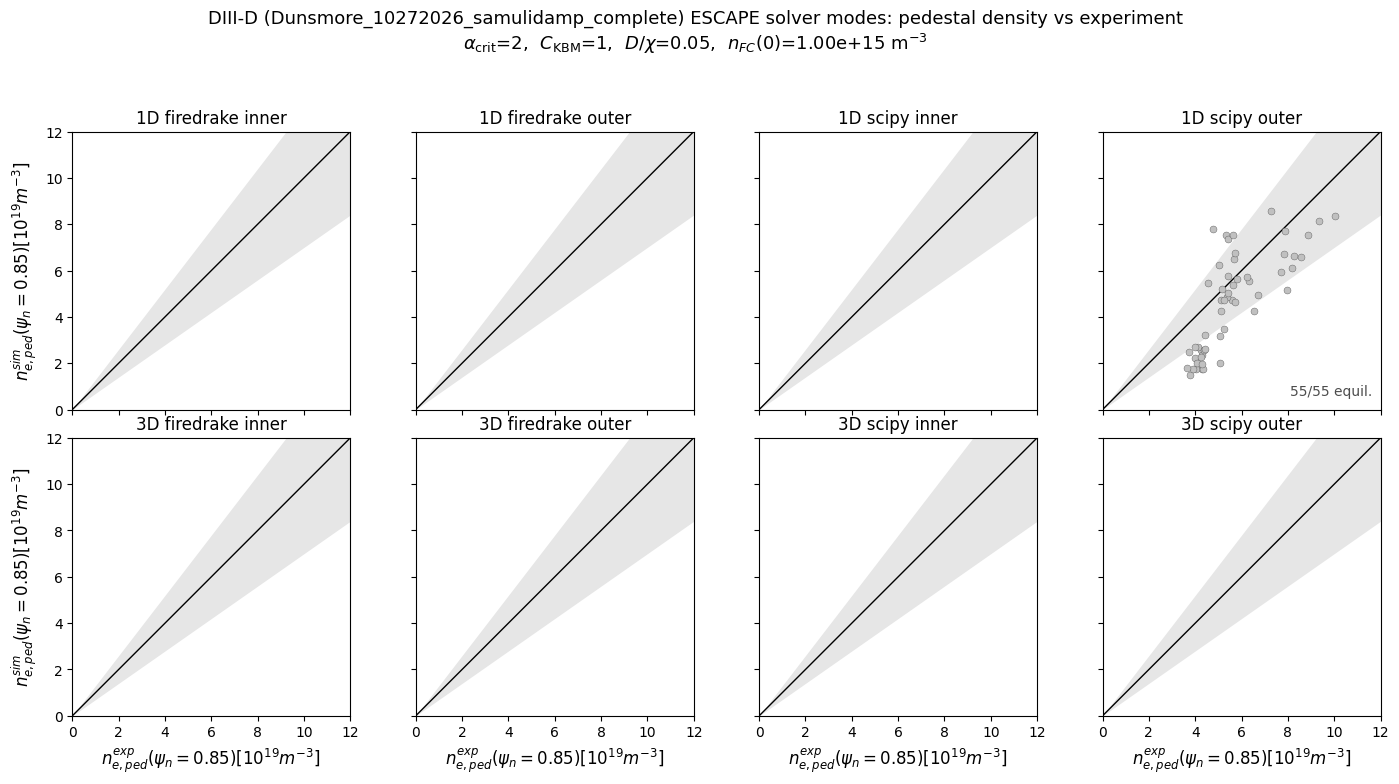

In [2]:
# --- 2 x 4 grid of simulated vs experimental n_e,ped, one panel per case ---

def fmt_free_params(fp):
    return (rf'$\alpha_{{\rm crit}}$={fp["alpha_crit"]:g},  '
            rf'$C_{{\rm KBM}}$={fp["C_KBM"]:g},  '
            rf'$D/\chi$={fp["De_chie_etg"]:g},  '
            rf'$n_{{FC}}(0)$={fp["nFC_x0"]:.2e} m$^{{-3}}$')

n_cols = len(SC_IMPLEMENTATIONS) * len(NE_GRAD_BC_LOCS)
fig, axes = plt.subplots(len(SC_MODELS), n_cols, figsize=(3.6 * n_cols, 3.9 * len(SC_MODELS)),
                         sharex=True, sharey=True, squeeze=False)

for k, case in enumerate(CASES):
    ax = axes[k // n_cols][k % n_cols]
    ax.fill_between([0, AXIS_MAX], [0, (1 - BAND_FRAC) * AXIS_MAX], [0, (1 + BAND_FRAC) * AXIS_MAX],
                    color='0.9', linewidth=0, zorder=0)
    ax.plot([0, AXIS_MAX], [0, AXIS_MAX], color='k', linewidth=1.0, zorder=0)
    r = results.get(case)
    if r is not None:
        ne_exp = np.array([x['ne_exp'] for x in r['runs']])
        ne_sim = np.array([x['ne_sim'] for x in r['runs']])
        ok = np.isfinite(ne_exp) & np.isfinite(ne_sim)
        ax.plot(ne_exp[ok], ne_sim[ok], 'o', color='silver', markersize=5,
                markeredgecolor='0.35', markeredgewidth=0.3, linestyle='none')
        n_tot = len(r['runs']) + len(r['failed']) + len(r['pending'])
        n_off = int(((ne_exp[ok] > AXIS_MAX) | (ne_sim[ok] > AXIS_MAX)).sum())
        note = f'{ok.sum()}/{n_tot} equil.' + (f'\n{n_off} beyond axis' if n_off else '')
        ax.text(0.97, 0.04, note, transform=ax.transAxes, ha='right', va='bottom',
                fontsize=10, color='0.3', zorder=5,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))
    ax.set_title(case_label(*case), fontsize=12)
    ax.set_xlim(0, AXIS_MAX)
    ax.set_ylim(0, AXIS_MAX)
    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(axis='both', labelsize=10)
    if k // n_cols == len(SC_MODELS) - 1:
        ax.set_xlabel(rf'$n_{{e,ped}}^{{exp}}(\psi_n={PSI_NE:g})[10^{{19}}m^{{-3}}]$', fontsize=12)
    if k % n_cols == 0:
        ax.set_ylabel(rf'$n_{{e,ped}}^{{sim}}(\psi_n={PSI_NE:g})[10^{{19}}m^{{-3}}]$', fontsize=12)

fp0 = next((r['free_params'] for r in results.values() if r['free_params']), None)
fig.suptitle(f'DIII-D (Dunsmore{RUN_SUFFIX}) ESCAPE solver modes: pedestal density vs experiment'
             + ('\n' + fmt_free_params(fp0) if fp0 else ''), fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.93), h_pad=2.0)
plt.show()

## Simulated vs experimental $p_{ped}$

Total pressure $p = n_e T_e + n_i T_i$ at $\psi_N = 0.85$, one point per converged equilibrium. The experimental value is built from the fitted profiles, $n_e T_e (1 + T_{rat})$, i.e. with the same $n_i = n_e$, $T_i = T_{rat} T_e$ closure the solver was fed; the simulated value uses the solved state's $n_e, T_e, n_i, T_i$.

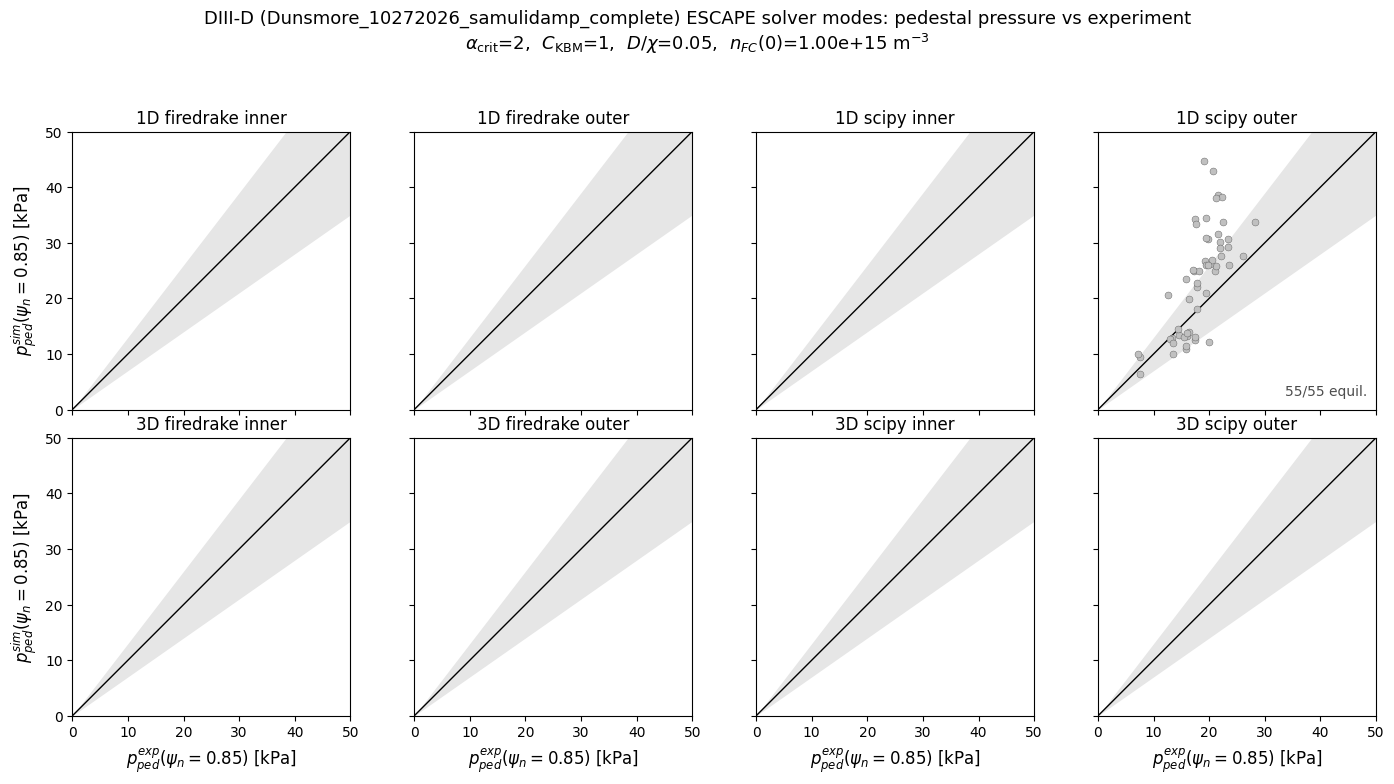

In [3]:
# --- 2 x 4 grid of simulated vs experimental p_ped, one panel per case ---

n_cols = len(SC_IMPLEMENTATIONS) * len(NE_GRAD_BC_LOCS)
fig, axes = plt.subplots(len(SC_MODELS), n_cols, figsize=(3.6 * n_cols, 3.9 * len(SC_MODELS)),
                         sharex=True, sharey=True, squeeze=False)

for k, case in enumerate(CASES):
    ax = axes[k // n_cols][k % n_cols]
    ax.fill_between([0, P_AXIS_MAX], [0, (1 - BAND_FRAC) * P_AXIS_MAX], [0, (1 + BAND_FRAC) * P_AXIS_MAX],
                    color='0.9', linewidth=0, zorder=0)
    ax.plot([0, P_AXIS_MAX], [0, P_AXIS_MAX], color='k', linewidth=1.0, zorder=0)
    r = results.get(case)
    if r is not None:
        p_exp = np.array([x['p_exp'] for x in r['runs']])
        p_sim = np.array([x['p_sim'] for x in r['runs']])
        ok = np.isfinite(p_exp) & np.isfinite(p_sim)
        ax.plot(p_exp[ok], p_sim[ok], 'o', color='silver', markersize=5,
                markeredgecolor='0.35', markeredgewidth=0.3, linestyle='none')
        n_tot = len(r['runs']) + len(r['failed']) + len(r['pending'])
        n_off = int(((p_exp[ok] > P_AXIS_MAX) | (p_sim[ok] > P_AXIS_MAX)).sum())
        note = f'{ok.sum()}/{n_tot} equil.' + (f'\n{n_off} beyond axis' if n_off else '')
        ax.text(0.97, 0.04, note, transform=ax.transAxes, ha='right', va='bottom',
                fontsize=10, color='0.3', zorder=5,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))
    ax.set_title(case_label(*case), fontsize=12)
    ax.set_xlim(0, P_AXIS_MAX)
    ax.set_ylim(0, P_AXIS_MAX)
    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(axis='both', labelsize=10)
    if k // n_cols == len(SC_MODELS) - 1:
        ax.set_xlabel(rf'$p_{{ped}}^{{exp}}(\psi_n={PSI_NE:g})$ [kPa]', fontsize=12)
    if k % n_cols == 0:
        ax.set_ylabel(rf'$p_{{ped}}^{{sim}}(\psi_n={PSI_NE:g})$ [kPa]', fontsize=12)

fp0 = next((r['free_params'] for r in results.values() if r['free_params']), None)
fig.suptitle(f'DIII-D (Dunsmore{RUN_SUFFIX}) ESCAPE solver modes: pedestal pressure vs experiment'
             + ('\n' + fmt_free_params(fp0) if fp0 else ''), fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.93), h_pad=2.0)
plt.show()

## First ESCAPE iteration (Saarelma-Connor only) vs experimental $n_{e,ped}$

Same as the density grid above, but the simulated $n_e$ is taken from the first ESCAPE iteration (`ne_and_Te_iter_0.npy`), i.e. the Saarelma-Connor solve on the experimental temperature profile before any EPEDNN feedback. Every run whose first iteration finished is included, including runs whose later iterations failed, so the counts differ from the converged-run grid.

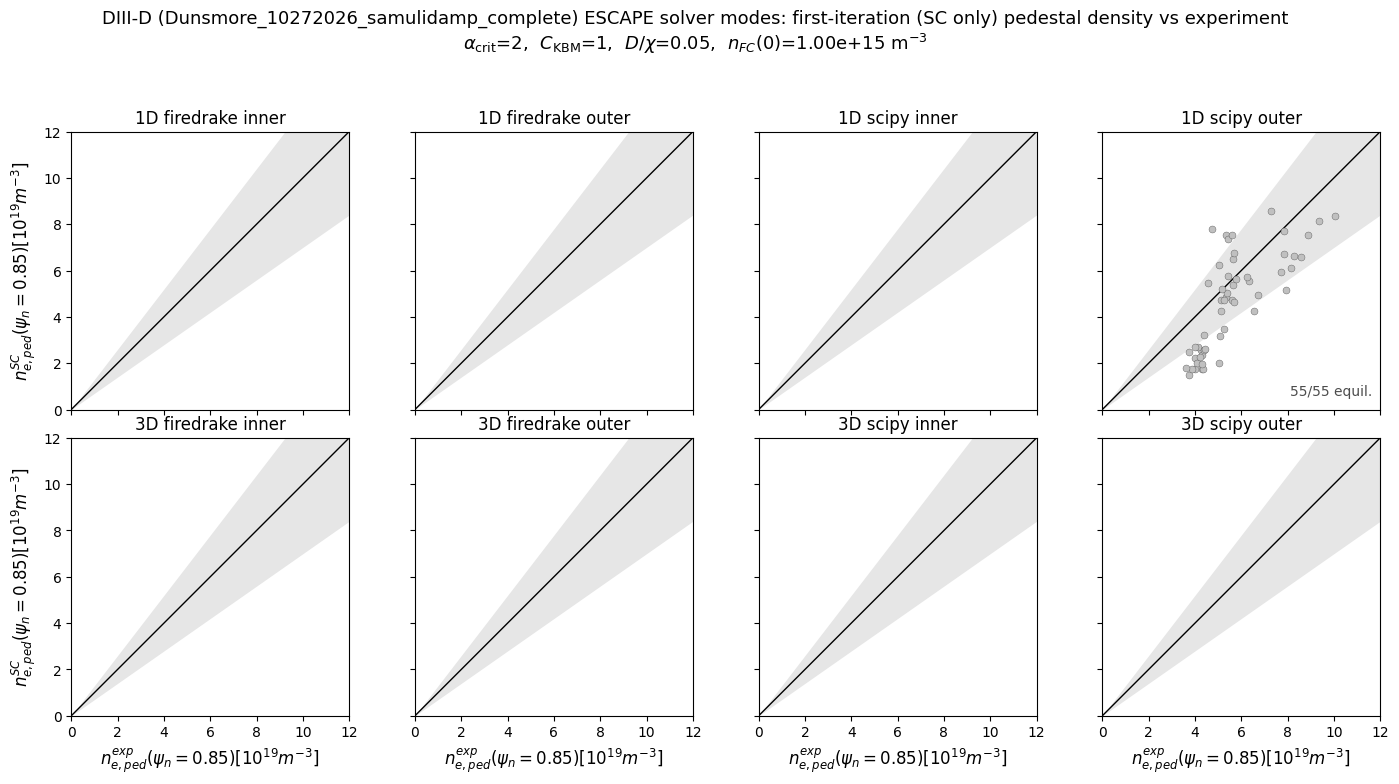

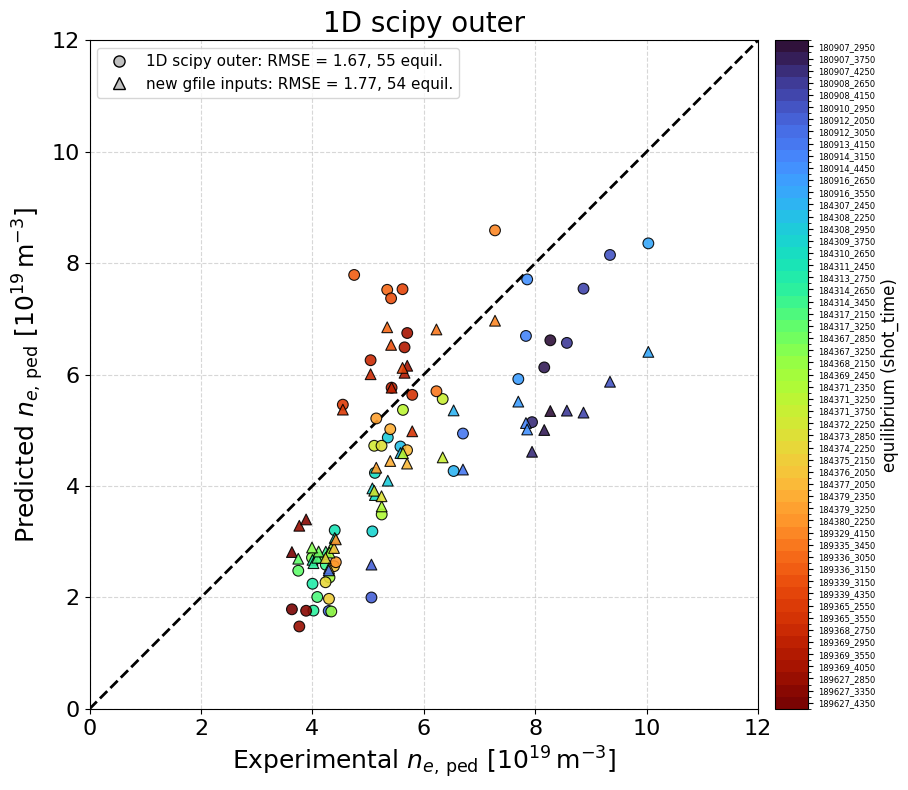

In [4]:
# --- 2 x 4 grid of first-iteration (SC only) vs experimental n_e,ped, one panel per case ---

n_cols = len(SC_IMPLEMENTATIONS) * len(NE_GRAD_BC_LOCS)
fig, axes = plt.subplots(len(SC_MODELS), n_cols, figsize=(3.6 * n_cols, 3.9 * len(SC_MODELS)),
                         sharex=True, sharey=True, squeeze=False)

for k, case in enumerate(CASES):
    ax = axes[k // n_cols][k % n_cols]
    ax.fill_between([0, AXIS_MAX], [0, (1 - BAND_FRAC) * AXIS_MAX], [0, (1 + BAND_FRAC) * AXIS_MAX],
                    color='0.9', linewidth=0, zorder=0)
    ax.plot([0, AXIS_MAX], [0, AXIS_MAX], color='k', linewidth=1.0, zorder=0)
    r = results.get(case)
    if r is not None:
        ne_exp = np.array([ne_exp_by_equil.get(x['equil'], np.nan) for x in r['first']])
        ne_sim = np.array([x['ne_sim'] for x in r['first']])
        ok = np.isfinite(ne_exp) & np.isfinite(ne_sim)
        ax.plot(ne_exp[ok], ne_sim[ok], 'o', color='silver', markersize=5,
                markeredgecolor='0.35', markeredgewidth=0.3, linestyle='none')
        n_tot = len(r['runs']) + len(r['failed']) + len(r['pending'])
        n_off = int(((ne_exp[ok] > AXIS_MAX) | (ne_sim[ok] > AXIS_MAX)).sum())
        note = f'{ok.sum()}/{n_tot} equil.' + (f'\n{n_off} beyond axis' if n_off else '')
        ax.text(0.97, 0.04, note, transform=ax.transAxes, ha='right', va='bottom',
                fontsize=10, color='0.3', zorder=5,
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=1.5))
    ax.set_title(case_label(*case), fontsize=12)
    ax.set_xlim(0, AXIS_MAX)
    ax.set_ylim(0, AXIS_MAX)
    ax.set_aspect('equal', adjustable='box')
    ax.tick_params(axis='both', labelsize=10)
    if k // n_cols == len(SC_MODELS) - 1:
        ax.set_xlabel(rf'$n_{{e,ped}}^{{exp}}(\psi_n={PSI_NE:g})[10^{{19}}m^{{-3}}]$', fontsize=12)
    if k % n_cols == 0:
        ax.set_ylabel(rf'$n_{{e,ped}}^{{SC}}(\psi_n={PSI_NE:g})[10^{{19}}m^{{-3}}]$', fontsize=12)

fp0 = next((r['free_params'] for r in results.values() if r['free_params']), None)
fig.suptitle(f'DIII-D (Dunsmore{RUN_SUFFIX}) ESCAPE solver modes: first-iteration (SC only) pedestal density vs experiment'
             + ('\n' + fmt_free_params(fp0) if fp0 else ''), fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.93), h_pad=2.0)
plt.show()

# --- single panel: first-iteration (SC only) 1D scipy outer vs experimental n_e,ped,
#     overlaid with the new-gfile-input results; colour = equilibrium (shared colorbar) ---

from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
import pandas as pd

NEW_GFILE_CSV = 'results_with_new_gfile_inputs_for_John.csv'
new_df = pd.read_csv(NEW_GFILE_CSV)

case = ('1D', 'scipy', 'outer')
r = results.get(case)
datasets = []   # (label, marker, equil, ne_exp, ne_sim)
if r is not None:
    equil = np.array([x['equil'] for x in r['first']])
    ne_exp = np.array([ne_exp_by_equil.get(e, np.nan) for e in equil])
    ne_sim = np.array([x['ne_sim'] for x in r['first']])
    datasets.append((case_label(*case), 'o', equil, ne_exp, ne_sim))
datasets.append(('new gfile inputs', '^', new_df['case'].to_numpy(str),
                 new_df['ne_exp_085'].to_numpy(float), new_df['ne_sim_085'].to_numpy(float)))

# One colour per equilibrium, shared by both datasets
all_equil = sorted({e for _, _, eq, xe, xs in datasets
                    for e, ok in zip(eq, np.isfinite(xe) & np.isfinite(xs)) if ok})
equil_idx = {e: k for k, e in enumerate(all_equil)}
cmap = ListedColormap(plt.cm.turbo(np.linspace(0, 1, len(all_equil))))
norm = BoundaryNorm(np.arange(len(all_equil) + 1) - 0.5, cmap.N)

fig, ax = plt.subplots(figsize=(9.5, 8.0))
handles = []
for label, marker, equil, ne_exp, ne_sim in datasets:
    ok = np.isfinite(ne_exp) & np.isfinite(ne_sim)
    rmse = np.sqrt(np.mean((ne_sim[ok] - ne_exp[ok]) ** 2))
    sc = ax.scatter(ne_exp[ok], ne_sim[ok], c=[equil_idx[e] for e in equil[ok]], cmap=cmap, norm=norm,
                    marker=marker, s=60, alpha=0.9, edgecolor='k', linewidth=0.8, zorder=3)
    handles.append(Line2D([], [], marker=marker, linestyle='none', markersize=8, markerfacecolor='silver',
                          markeredgecolor='k', label=f'{label}: RMSE = {rmse:.2f}, {ok.sum()} equil.'))
ax.plot([0, AXIS_MAX], [0, AXIS_MAX], color='k', linestyle='--', linewidth=2, zorder=2)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
ax.set_xlim(0, AXIS_MAX)
ax.set_ylim(0, AXIS_MAX)
ax.set_aspect('equal', adjustable='box')
ax.set_xticks(np.arange(0, AXIS_MAX + 1, 2))
ax.set_yticks(np.arange(0, AXIS_MAX + 1, 2))
ax.tick_params(axis='both', labelsize=16)
ax.set_xlabel(r'Experimental $n_{e,\,\mathrm{ped}}$ [$10^{19}\,\mathrm{m^{-3}}$]', fontsize=18)
ax.set_ylabel(r'Predicted $n_{e,\,\mathrm{ped}}$ [$10^{19}\,\mathrm{m^{-3}}$]', fontsize=18)
ax.set_title(case_label(*case), fontsize=20)
ax.legend(handles=handles, loc='upper left', fontsize=11, frameon=True)
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.05, pad=0.02,
                    ticks=np.arange(len(all_equil)))
cbar.ax.set_yticklabels(all_equil, fontsize=6)
cbar.ax.invert_yaxis()
cbar.set_label('equilibrium (shot_time)', fontsize=12)
fig.tight_layout()
plt.show()

findfont: Font family 'EB Garamond' not found.
findfont: Font family 'Garamond' not found.
findfont: Font family 'Palatino Linotype' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'Garamond' not found.
findfont: Font family 'Palatino Linotype' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'Garamond' not found.
findfont: Font family 'Palatino Linotype' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'Garamond' not found.
findfont: Font family 'Palatino Linotype' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'Garamond' not found.
findfont: Font family 'Palatino Linotype' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'Garamond' not found.
findfont: Font family 'Palatino Linotype' not found.
findfont: Font family 'EB Garamond' not found.
findfont: Font family 'Garamond' not found.
findfont: Font family 'Palatino Linotype' not

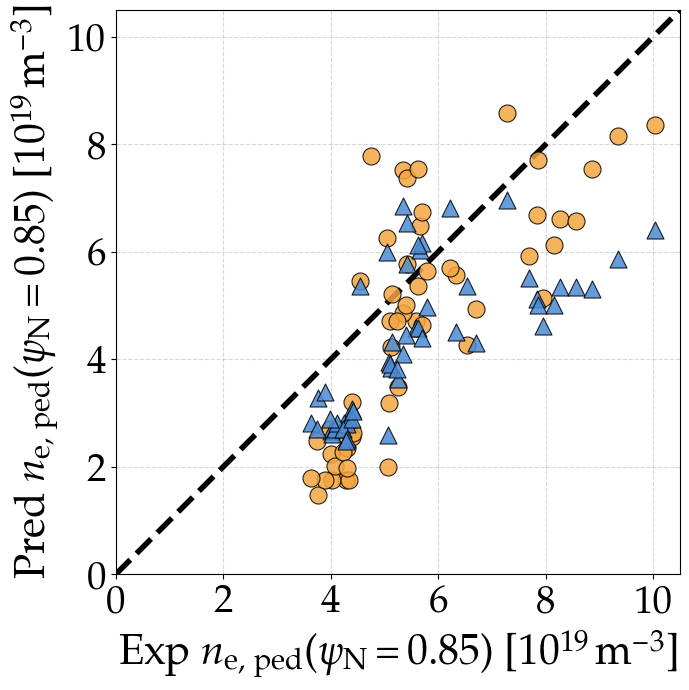

In [9]:
# --- single panel: same overlay as above, without the colorbar; colour = dataset ---
# (reuses `case` and `datasets` from the previous cell)

DATASET_COLORS = ['#F5A640', '#4C8BD6']

# --- legend settings (edit freely) ---
# One entry per dataset; None -> default '<label>: RMSE = ..., N equil.'
# Custom strings may use {label}, {rmse}, {n} placeholders, e.g. '{label} (RMSE {rmse:.2f})'
LEGEND_LABELS   = ['Europed Implementation [5-8]', 'OFT Implementation']
LEGEND_LOC      = 'upper left'
fs = 30
LEGEND_FRAMEON  = True
SHOW_LEGEND     = True
# Tick/legend font: EB Garamond if installed, else the closest available old-style serif
FONT_FAMILY     = ['EB Garamond', 'Garamond', 'P052', 'Palatino Linotype', 'DejaVu Serif']

# Math text ($...$ in the axis labels) needs a single installed family: use the first available
from matplotlib import font_manager as _fm
_installed = {f.name for f in _fm.fontManager.ttflist}
_math_font = next((f for f in FONT_FAMILY if f in _installed), 'DejaVu Serif')
_MATH_RC = {'mathtext.fontset': 'custom', 'mathtext.rm': _math_font,
            'mathtext.it': f'{_math_font}:italic', 'mathtext.bf': f'{_math_font}:bold'}
_old_rc = {k: plt.rcParams[k] for k in _MATH_RC}
plt.rcParams.update(_MATH_RC)   # restored after plt.show()

fig, ax = plt.subplots(figsize=(7.7, 7.0))
for (label, marker, equil, ne_exp, ne_sim), color, leg in zip(datasets, DATASET_COLORS, LEGEND_LABELS):
    ok = np.isfinite(ne_exp) & np.isfinite(ne_sim)
    rmse = np.sqrt(np.mean((ne_sim[ok] - ne_exp[ok]) ** 2))
    ax.scatter(ne_exp[ok], ne_sim[ok], marker=marker, s=150, color=color, alpha=0.85,
               edgecolor='k', linewidth=0.8, zorder=3,
               label=(f'{label}: RMSE = {rmse:.2f}, {ok.sum()} equil.' if leg is None
                      else leg.format(label=label, rmse=rmse, n=ok.sum())))
ax.plot([0, AXIS_MAX], [0, AXIS_MAX], color='k', linestyle='--', linewidth=4, zorder=2)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
ax.set_aspect('equal', adjustable='box')
ax.set_xticks(np.arange(0, AXIS_MAX + 1, 2))
ax.set_yticks(np.arange(0, AXIS_MAX + 1, 2))
ax.tick_params(axis='both', labelsize=fs-2)
for t in ax.get_xticklabels() + ax.get_yticklabels():
    t.set_fontfamily(FONT_FAMILY)
# ax.set_xlabel(r'Experimental $n_{e,\,\mathrm{ped}}$ [$10^{19}\,\mathrm{m^{-3}}$]', fontsize=18)
# ax.set_ylabel(r'Predicted $n_{e,\,\mathrm{ped}}$ [$10^{19}\,\mathrm{m^{-3}}$]', fontsize=18)
ax.set_ylabel(rf'Pred $n_{{\mathrm{{e,\,ped}}}}(\psi_{{\mathrm{{N}}}}={PSI_NE:g})$ [$10^{{19}}\,\mathrm{{m^{{-3}}}}$]', fontsize=fs)
ax.set_xlabel(rf'Exp $n_{{\mathrm{{e,\,ped}}}}(\psi_{{\mathrm{{N}}}}={PSI_NE:g})$ [$10^{{19}}\,\mathrm{{m^{{-3}}}}$]', fontsize=fs)
# ax.set_title(case_label(*case), fontsize=20)
ax.xaxis.label.set_fontfamily(FONT_FAMILY)
ax.yaxis.label.set_fontfamily(FONT_FAMILY)
# if SHOW_LEGEND:
#     # placed above the axes (outside the plotting area), one entry per row
#     ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=1,
#               prop={'family': FONT_FAMILY, 'size': fs-2}, frameon=LEGEND_FRAMEON)
ax.set_xlim(0, 10.5)
ax.set_ylim(0, 10.5)
fig.tight_layout()
fig.savefig('Dunsmore_valid_APS.png',dpi=600)
plt.show()
plt.rcParams.update(_old_rc)


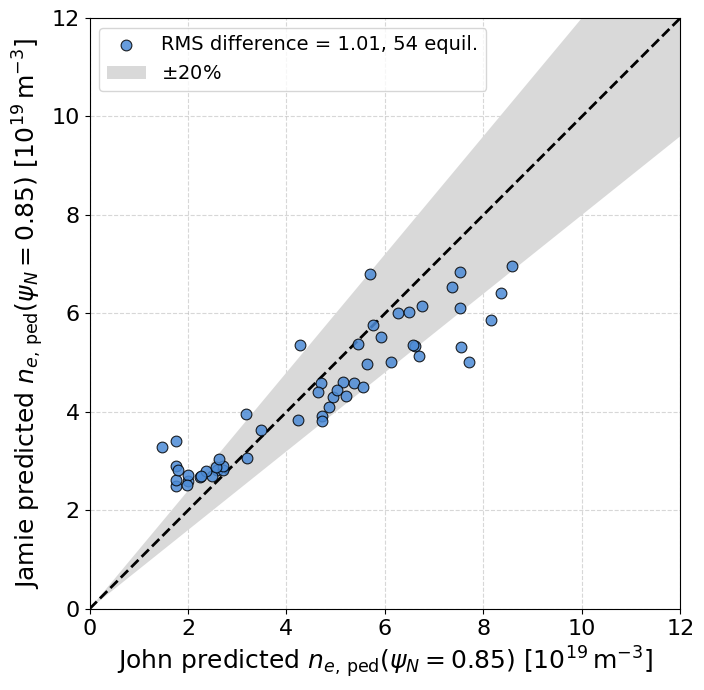

In [6]:
# --- single panel: predicted n_e,ped(psi_N=0.85), new gfile inputs vs 1D scipy outer (first iteration) ---
# (reuses `datasets` from the cell above; points matched by equilibrium name)

(lab_a, _, eq_a, _, ne_a), (lab_b, _, eq_b, _, ne_b) = datasets
ne_b_by_equil = dict(zip(eq_b, ne_b))
ne_x = ne_a
ne_y = np.array([ne_b_by_equil.get(e, np.nan) for e in eq_a])
ok = np.isfinite(ne_x) & np.isfinite(ne_y)
rmse = np.sqrt(np.mean((ne_y[ok] - ne_x[ok]) ** 2))

fig, ax = plt.subplots(figsize=(7.7, 7.0))
ax.scatter(ne_x[ok], ne_y[ok], marker='o', s=60, color='#4C8BD6', alpha=0.85,
           edgecolor='k', linewidth=0.8, zorder=3,
           label=f'RMS difference = {rmse:.2f}, {ok.sum()} equil.')
RUN_BAND_FRAC = 0.20                          # shaded +/- band around the 1:1 line
ax.fill_between([0, AXIS_MAX], [0, (1 - RUN_BAND_FRAC) * AXIS_MAX], [0, (1 + RUN_BAND_FRAC) * AXIS_MAX],
                color='0.85', linewidth=0, zorder=1, label=rf'$\pm${RUN_BAND_FRAC:.0%}')
ax.plot([0, AXIS_MAX], [0, AXIS_MAX], color='k', linestyle='--', linewidth=2, zorder=2)
ax.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
ax.set_xlim(0, AXIS_MAX)
ax.set_ylim(0, AXIS_MAX)
ax.set_aspect('equal', adjustable='box')
ax.set_xticks(np.arange(0, AXIS_MAX + 1, 2))
ax.set_yticks(np.arange(0, AXIS_MAX + 1, 2))
ax.tick_params(axis='both', labelsize=16)
ax.set_xlabel(rf'John predicted $n_{{e,\,\mathrm{{ped}}}}(\psi_N={PSI_NE:g})$ [$10^{{19}}\,\mathrm{{m^{{-3}}}}$]', fontsize=18)
ax.set_ylabel(rf'Jamie predicted $n_{{e,\,\mathrm{{ped}}}}(\psi_N={PSI_NE:g})$ [$10^{{19}}\,\mathrm{{m^{{-3}}}}$]', fontsize=18)
# ax.set_title('Predicted pedestal density: run vs run', fontsize=18)
ax.legend(loc='upper left', fontsize=14, frameon=True)
fig.tight_layout()
plt.show()


outputs/DIIIDDunsmore_ESCAPE_1Dscipyouter_10272026_samulidamp_complete/189329_4150/neouter0_fp0: Picard converged in 4 iterations, picard_relax = [[1, 1.0], [11, 0.5], [31, 0.2]]


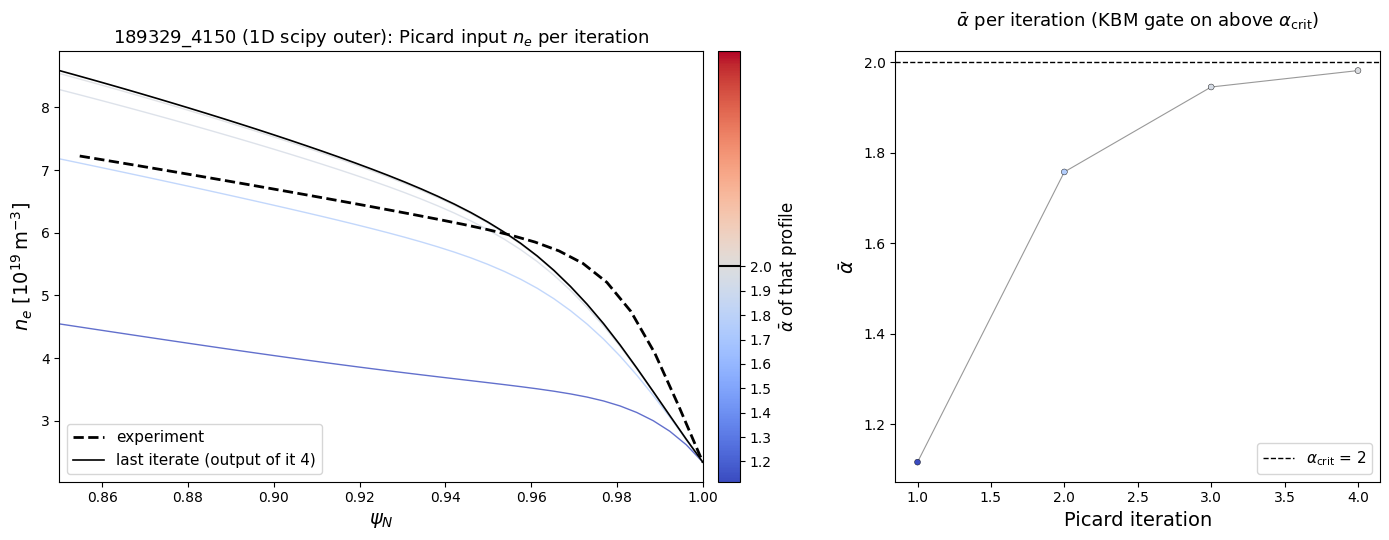

In [7]:
# --- Per-Picard-iteration n_e of one equilibrium, coloured by alpha_bar ---
# Read from the run loaded above (case_dir(...) / EQUIL_DBG / RUN_SUBDIR, i.e. RUN_SUFFIX):
# out_dict['state']['picard_info']['history'] of the SC solve (with ESCAPE_iter_max > 1 this
# is the last ESCAPE iteration's solve). Only converged runs carry it: failed.npy stores
# just the error message.
# Needs the TEMP DEBUG 'x' / 'ne_in' / 'ne_out' history keys in solver_1d.solve_sc_scipy.
# Each iteration's alpha_bar is computed from its input n_e ('ne_in'), so that is the
# profile drawn in its colour.

from matplotlib.colors import TwoSlopeNorm
from scipy.interpolate import interp1d

EQUIL_DBG = '189329_4150'
MODEL_DBG, IMPL_DBG, BC_DBG = '1D', 'scipy', 'outer'

run_dir_dbg = case_dir(MODEL_DBG, IMPL_DBG, BC_DBG) / EQUIL_DBG / RUN_SUBDIR
if not (run_dir_dbg / 'out_dict.npy').exists():
    err = (load_out_dict(run_dir_dbg / 'failed.npy')['error']
           if (run_dir_dbg / 'failed.npy').exists() else 'no output yet')
    raise FileNotFoundError(f'{run_dir_dbg}: no out_dict.npy, so no Picard history saved ({err})')
d_dbg = load_out_dict(run_dir_dbg / 'out_dict.npy')
s_dbg = d_dbg['state']
picard_info = s_dbg['picard_info']
hist = picard_info['history']
alpha_crit = float(s_dbg['alpha_crit'])
print(f'{run_dir_dbg}: Picard {"converged" if picard_info["converged"] else "did not converge"} '
      f'in {picard_info["iterations"]} iterations, picard_relax = {s_dbg["kbm_info"]["picard_relax"]}')

# Experimental n_e, as fed to the run
psin_ne_exp = np.asarray(d_dbg['profiles']['psin_ne'], dtype=float)
ne_exp = np.asarray(d_dbg['profiles']['n_e'], dtype=float)

# Solver x grid -> psi_N
x_to_psiN = interp1d(np.asarray(s_dbg['x_init'], dtype=float), np.asarray(s_dbg['psi_N_pres'], dtype=float),
                     bounds_error=False, fill_value='extrapolate')
alpha_bar = np.array([h['alpha_bar'] for h in hist])
norm = TwoSlopeNorm(vcenter=alpha_crit, vmin=min(alpha_bar.min(), alpha_crit - 1e-3),
                    vmax=max(alpha_bar.max(), alpha_crit + 1e-3))
cmap = plt.cm.coolwarm

fig, (ax, ax_a) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={'width_ratios': [1.6, 1]})
for h in hist:
    ax.plot(x_to_psiN(h['x']), h['ne_in'] / 1e19, color=cmap(norm(h['alpha_bar'])),
            linewidth=1.0, alpha=0.8)
psi_lo = float(x_to_psiN(hist[0]['x']).min())
in_ped = psin_ne_exp >= psi_lo
ax.plot(psin_ne_exp[in_ped], ne_exp[in_ped] / 1e19, 'k--', linewidth=2, label='experiment')
ax.plot(x_to_psiN(hist[-1]['x']), hist[-1]['ne_out'] / 1e19, 'k-', linewidth=1.2,
        label=f'last iterate (output of it {hist[-1]["iteration"]})')
ax.set_xlim(psi_lo, 1.0)
ax.set_xlabel(r'$\psi_N$', fontsize=14)
ax.set_ylabel(r'$n_e$ [$10^{19}\,\mathrm{m^{-3}}$]', fontsize=14)
ax.set_title(f'{EQUIL_DBG} ({case_label(MODEL_DBG, IMPL_DBG, BC_DBG)}): '
             f'Picard input $n_e$ per iteration', fontsize=13)
ax.legend(loc='lower left', fontsize=11)
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, pad=0.02)
cbar.set_label(r'$\bar\alpha$ of that profile', fontsize=12)
cbar.ax.axhline(alpha_crit, color='k', linewidth=1.5)

its = np.array([h['iteration'] for h in hist])
ax_a.plot(its, alpha_bar, color='0.6', linewidth=0.8, zorder=1)
ax_a.scatter(its, alpha_bar, c=alpha_bar, cmap=cmap, norm=norm, s=18, edgecolor='k',
             linewidth=0.3, zorder=2)
ax_a.axhline(alpha_crit, color='k', linestyle='--', linewidth=1,
             label=rf'$\alpha_{{\rm crit}}$ = {alpha_crit:g}')
# Iterations where a picard_relax schedule changes the relaxation (history key absent in older runs)
relax = [h.get('picard_relax') for h in hist]
for it_k, r_prev, r_k in zip(its[1:], relax[:-1], relax[1:]):
    if r_k is not None and r_k != r_prev:
        ax_a.axvline(it_k - 0.5, color='0.4', linestyle=':', linewidth=1)
        ax_a.text(it_k - 0.3, 1.0, rf'$\omega$={r_k:g}', transform=ax_a.get_xaxis_transform(),
                  va='bottom', fontsize=10)
ax_a.set_xlabel('Picard iteration', fontsize=14)
ax_a.set_ylabel(r'$\bar\alpha$', fontsize=14)
ax_a.set_title(r'$\bar\alpha$ per iteration (KBM gate on above $\alpha_{\rm crit}$)', fontsize=13, pad=18)
ax_a.legend(fontsize=11)
fig.tight_layout()
plt.show()

## Runtime and convergence

Mean `ESCAPE_runtime` (wall time of `ESCAPE_solve`) over the converged equilibria of each case; failed runs are excluded. Error bars are the standard deviation over equilibria. Note the cases converge on different subsets of equilibria, so the means are not over identical sets.

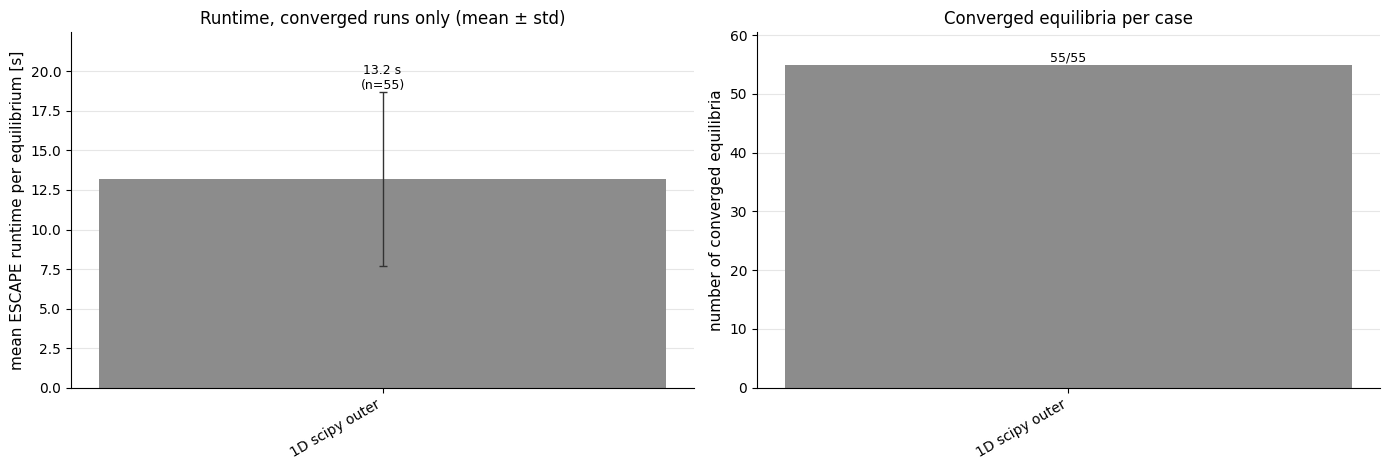

1D scipy outer         converged  55/55   runtime    13.2 ±    5.5 s


In [8]:
# --- Bar charts: mean runtime of converged runs, and number of converged equilibria ---

labels = [case_label(*c) for c in results]
x = np.arange(len(labels))
BAR_COLOR = '0.55'

runtimes = [np.array([r['runtime'] for r in res['runs']]) for res in results.values()]
t_mean = np.array([t.mean() if t.size else np.nan for t in runtimes])
t_std = np.array([t.std() if t.size else np.nan for t in runtimes])
n_conv = np.array([len(res['runs']) for res in results.values()])
n_tot = np.array([len(res['runs']) + len(res['failed']) + len(res['pending'])
                  for res in results.values()])

fig, (ax_t, ax_n) = plt.subplots(1, 2, figsize=(14, 4.8))

ax_t.bar(x, t_mean, yerr=t_std, color=BAR_COLOR, width=0.7, capsize=3,
         error_kw={'elinewidth': 1, 'ecolor': '0.2'})
for xi, m, s, n in zip(x, t_mean, t_std, n_conv):
    if np.isfinite(m):
        ax_t.text(xi, m + s, f'{m:.1f} s\n(n={n})', ha='center', va='bottom', fontsize=9)
ax_t.set_ylim(0, np.nanmax(t_mean + t_std) * 1.2)
ax_t.set_ylabel('mean ESCAPE runtime per equilibrium [s]', fontsize=11)
ax_t.set_title('Runtime, converged runs only (mean ± std)', fontsize=12)

ax_n.bar(x, n_conv, color=BAR_COLOR, width=0.7)
for xi, n, t in zip(x, n_conv, n_tot):
    ax_n.text(xi, n, f'{n}/{t}', ha='center', va='bottom', fontsize=9)
ax_n.set_ylim(0, n_tot.max() * 1.1)
ax_n.set_ylabel('number of converged equilibria', fontsize=11)
ax_n.set_title('Converged equilibria per case', fontsize=12)

for ax in (ax_t, ax_n):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha='right', fontsize=10)
    ax.grid(axis='y', color='0.9', linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)

fig.tight_layout()
plt.show()

for lab, m, s, n, t in zip(labels, t_mean, t_std, n_conv, n_tot):
    print(f'{lab:22s} converged {n:3d}/{t}   runtime {m:7.1f} ± {s:6.1f} s')